In [ ]:
!wget https://dcapswoz.ict.usc.edu/wwwedaic/labels/train_split.csv
!wget https://dcapswoz.ict.usc.edu/wwwedaic/labels/dev_split.csv
!wget https://dcapswoz.ict.usc.edu/wwwedaic/labels/test_split.csv
!wget https://dcapswoz.ict.usc.edu/wwwedaic/labels/Detailed_PHQ8_Labels.csv
!wget https://dcapswoz.ict.usc.edu/wwwedaic/labels/detailed_lables.csv

--2026-09-24 10:25:03--  https://dcapswoz.ict.usc.edu/wwwedaic/labels/train_split.csv
Resolving dcapswoz.ict.usc.edu (dcapswoz.ict.usc.edu)... 141.193.213.21, 141.193.213.20
Connecting to dcapswoz.ict.usc.edu (dcapswoz.ict.usc.edu)|141.193.213.21|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3198 (3.1K) [text/csv]
Saving to: ‘train_split.csv’

train_split.csv     100%[===================>]   3.12K  --.-KB/s    in 0s      

2026-09-24 10:25:04 (34.2 MB/s) - ‘train_split.csv’ saved [3198/3198]

--2026-09-24 10:25:04--  https://dcapswoz.ict.usc.edu/wwwedaic/labels/dev_split.csv
Resolving dcapswoz.ict.usc.edu (dcapswoz.ict.usc.edu)... 141.193.213.21, 141.193.213.20
Connecting to dcapswoz.ict.usc.edu (dcapswoz.ict.usc.edu)|141.193.213.21|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1137 (1.1K) [text/csv]
Saving to: ‘dev_split.csv’

dev_split.csv       100%[===================>]   1.11K  --.-KB/s    in 0s      

2026-09-24 10:25:04 (21

In [ ]:
import pandas as pd

train = pd.read_csv("train_split.csv")
dev = pd.read_csv("dev_split.csv")
test = pd.read_csv("test_split.csv")

print(train.shape)
print(dev.shape)
print(test.shape)

display(train.head())
display(dev.head())
display(test.head())

(163, 6)
(56, 6)
(56, 6)


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity
0,302,male,0,4,0,28
1,303,female,0,0,0,17
2,304,female,0,6,0,20
3,305,male,0,7,0,28
4,307,female,0,4,0,23


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity
0,300,male,0,2,0,25
1,301,male,0,3,0,17
2,306,female,0,0,0,21
3,317,male,0,8,1,51
4,320,female,0,11,1,64


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity
0,600,female,0,5,0,23.0
1,602,female,1,13,1,67.0
2,604,male,1,12,0,30.0
3,605,male,0,2,0,23.0
4,606,female,0,5,0,46.0


In [ ]:
!wget https://dcapswoz.ict.usc.edu/wwwedaic/data/300_P.tar.gz

--2026-09-24 10:26:34--  https://dcapswoz.ict.usc.edu/wwwedaic/data/300_P.tar.gz
Resolving dcapswoz.ict.usc.edu (dcapswoz.ict.usc.edu)... 141.193.213.20, 141.193.213.21
Connecting to dcapswoz.ict.usc.edu (dcapswoz.ict.usc.edu)|141.193.213.20|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 279811302 (267M) [application/octet-stream]
Saving to: ‘300_P.tar.gz’

300_P.tar.gz        100%[===================>] 266.85M  81.1MB/s    in 5.2s    

2026-09-24 10:26:40 (51.6 MB/s) - ‘300_P.tar.gz’ saved [279811302/279811302]



In [ ]:
!tar -xzf 300_P.tar.gz

In [ ]:
all_ids = pd.concat([
    train["Participant_ID"],
    dev["Participant_ID"],
    test["Participant_ID"]
])

print("Total rows:", len(all_ids))
print("Unique participants:", all_ids.nunique())

print("Train unique:", train["Participant_ID"].nunique())
print("Dev unique:", dev["Participant_ID"].nunique())
print("Test unique:", test["Participant_ID"].nunique())

print("Duplicates:", all_ids[all_ids.duplicated()].unique())

Total rows: 275
Unique participants: 275
Train unique: 163
Dev unique: 56
Test unique: 56
Duplicates: []


In [ ]:
print(
    set(train["Participant_ID"]) & set(dev["Participant_ID"])
)

print(
    set(train["Participant_ID"]) & set(test["Participant_ID"])
)

print(
    set(dev["Participant_ID"]) & set(test["Participant_ID"])
)

set()
set()
set()


In [ ]:
train["Split"] = "Train"
dev["Split"] = "Dev"
test["Split"] = "Test"

df = pd.concat([train, dev, test], ignore_index=True)

print(df.shape)
display(df.head())
display(df.describe(include="all"))

(275, 7)


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity,Split
0,302,male,0,4,0,28.0,Train
1,303,female,0,0,0,17.0,Train
2,304,female,0,6,0,20.0,Train
3,305,male,0,7,0,28.0,Train
4,307,female,0,4,0,23.0,Train


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity,Split
count,275.000000,275,275.000000,275.000000,275.000000,273.000000,275
unique,NaN,4,NaN,NaN,NaN,NaN,3
top,NaN,male,NaN,NaN,NaN,NaN,Train
freq,NaN,168,NaN,NaN,NaN,NaN,163
mean,477.858182,NaN,0.240000,6.941818,0.316364,36.443223,NaN
std,131.717175,NaN,0.427862,6.108230,0.465905,17.391404,NaN
min,300.000000,NaN,0.000000,0.000000,0.000000,17.000000,NaN
25%,369.500000,NaN,0.000000,2.000000,0.000000,22.000000,NaN
50%,440.000000,NaN,0.000000,6.000000,0.000000,30.000000,NaN
75%,622.500000,NaN,0.000000,11.000000,1.000000,50.000000,NaN


In [ ]:
print(df["PHQ_Binary"].value_counts())
print(df["PHQ_Binary"].value_counts(normalize=True) * 100)

PHQ_Binary
0    209
1     66
Name: count, dtype: int64
PHQ_Binary
0    76.0
1    24.0
Name: proportion, dtype: float64


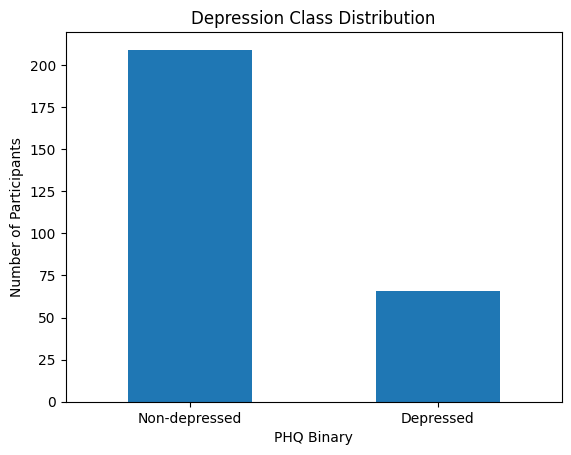

In [ ]:
#CLASS DISTRIBUTION
import matplotlib.pyplot as plt

df["PHQ_Binary"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("PHQ Binary")
plt.ylabel("Number of Participants")
plt.title("Depression Class Distribution")
plt.xticks([0, 1], ["Non-depressed", "Depressed"], rotation=0)
plt.show()

count    275.000000
mean       6.941818
std        6.108230
min        0.000000
25%        2.000000
50%        6.000000
75%       11.000000
max       23.000000
Name: PHQ_Score, dtype: float64


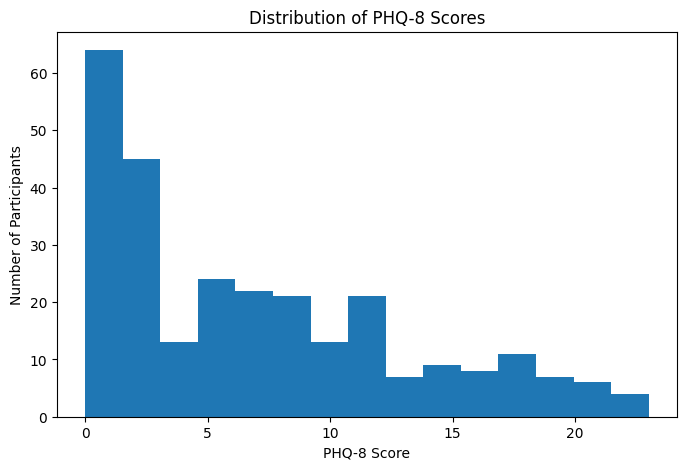

In [ ]:
#PHQ SCORE DISTRIBUTION
print(df["PHQ_Score"].describe())
plt.figure(figsize=(8,5))

plt.hist(df["PHQ_Score"], bins=15)

plt.xlabel("PHQ-8 Score")
plt.ylabel("Number of Participants")
plt.title("Distribution of PHQ-8 Scores")

plt.show()

<Figure size 700x500 with 0 Axes>

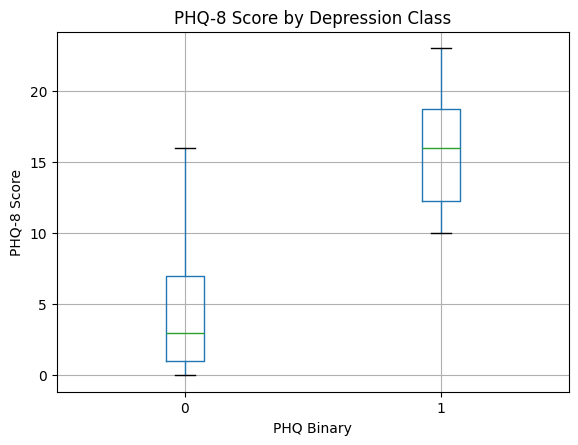

In [ ]:
#PHQ SCORE BY DEPRESSION CLASS
plt.figure(figsize=(7,5))

df.boxplot(
    column="PHQ_Score",
    by="PHQ_Binary"
)

plt.title("PHQ-8 Score by Depression Class")
plt.suptitle("")
plt.xlabel("PHQ Binary")
plt.ylabel("PHQ-8 Score")

plt.show()

PCL-C (PTSD)
0    188
1     87
Name: count, dtype: int64
count    273.000000
mean      36.443223
std       17.391404
min       17.000000
25%       22.000000
50%       30.000000
75%       50.000000
max       85.000000
Name: PTSD Severity, dtype: float64


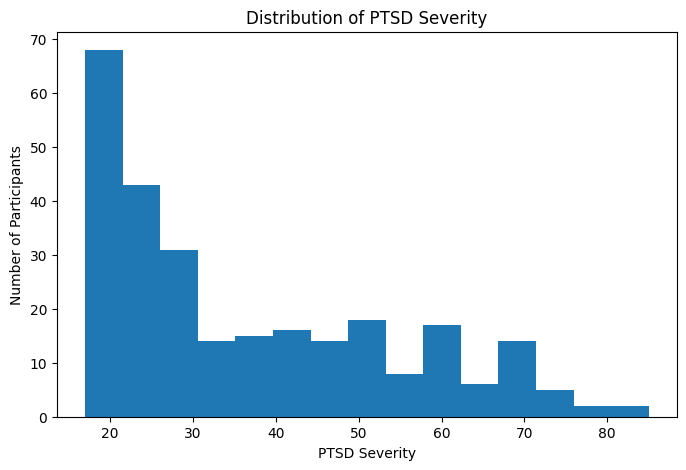

In [ ]:
#PTSD EDA
print(df["PCL-C (PTSD)"].value_counts())
print(df["PTSD Severity"].describe())
plt.figure(figsize=(8,5))

plt.hist(df["PTSD Severity"].dropna(), bins=15)

plt.xlabel("PTSD Severity")
plt.ylabel("Number of Participants")
plt.title("Distribution of PTSD Severity")

plt.show()

Gender
male       168
female     103
female       2
male         2
Name: count, dtype: int64


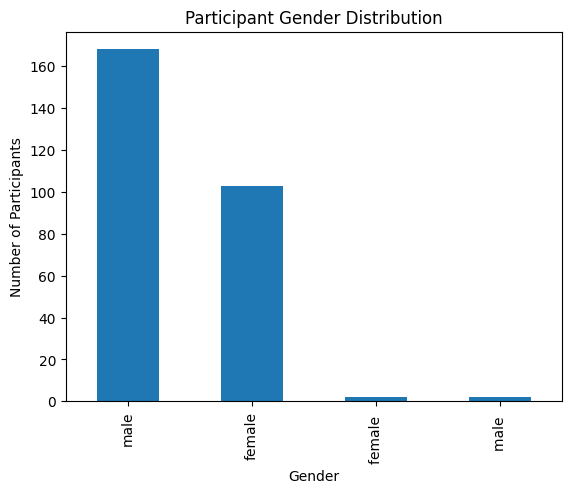

In [ ]:
#GENDER DISTRIBUTION
print(df["Gender"].value_counts())
df["Gender"].value_counts().plot(kind="bar")

plt.xlabel("Gender")
plt.ylabel("Number of Participants")
plt.title("Participant Gender Distribution")

plt.show()

In [ ]:
!find 300_P -maxdepth 2 -type f | sort

300_P/300_AUDIO.wav
300_P/300_Transcript.csv
300_P/features/300_BoAW_openSMILE_2.3.0_eGeMAPS.csv
300_P/features/300_BoAW_openSMILE_2.3.0_MFCC.csv
300_P/features/300_BoVW_openFace_2.1.0_Pose_Gaze_AUs.csv
300_P/features/300_CNN_ResNet.mat
300_P/features/300_CNN_VGG.mat
300_P/features/300_densenet201.csv
300_P/features/300_OpenFace2.1.0_Pose_gaze_AUs.csv
300_P/features/300_OpenSMILE2.3.0_egemaps.csv
300_P/features/300_OpenSMILE2.3.0_mfcc.csv
300_P/features/300_vgg16.csv


In [ ]:
!du -h 300_P/*
!du -sh 300_P

20M	300_P/300_AUDIO.wav
8.0K	300_P/300_Transcript.csv
553M	300_P/features
573M	300_P


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

eg = pd.read_csv(
    "300_P/features/300_OpenSMILE2.3.0_egemaps.csv",
    sep=";"
)

mfcc = pd.read_csv(
    "300_P/features/300_OpenSMILE2.3.0_mfcc.csv",
    sep=";"
)

print("eGeMAPS shape:", eg.shape)
print("MFCC shape:", mfcc.shape)

display(eg.head())
display(mfcc.head())

eGeMAPS shape: (64846, 25)
MFCC shape: (64848, 41)


,name,frameTime,Loudness_sma3,alphaRatio_sma3,hammarbergIndex_sma3,slope0-500_sma3,slope500-1500_sma3,spectralFlux_sma3,mfcc1_sma3,mfcc2_sma3,...,HNRdBACF_sma3nz,logRelF0-H1-H2_sma3nz,logRelF0-H1-A3_sma3nz,F1frequency_sma3nz,F1bandwidth_sma3nz,F1amplitudeLogRelF0_sma3nz,F2frequency_sma3nz,F2amplitudeLogRelF0_sma3nz,F3frequency_sma3nz,F3amplitudeLogRelF0_sma3nz
0,'unknown',0.00,0.091229,-18.75141,27.44206,-0.004226,-0.015931,0.011352,21.34628,12.856840,...,0.0,0.0,0.0,617.9512,1589.331,-201.0,1197.209,-201.0,2354.411,-201.0
1,'unknown',0.01,0.102588,-18.18413,25.72624,-0.006797,-0.017402,0.019224,22.80198,8.518313,...,0.0,0.0,0.0,673.9617,1387.229,-201.0,1561.150,-201.0,2680.610,-201.0
2,'unknown',0.02,0.117007,-15.78444,21.95449,-0.002153,-0.019206,0.030875,23.58895,1.987332,...,0.0,0.0,0.0,730.0425,1205.903,-201.0,1918.616,-201.0,2984.160,-201.0
3,'unknown',0.03,0.125157,-13.70766,17.00834,-0.004247,-0.021796,0.026580,22.81944,-0.059005,...,0.0,0.0,0.0,719.3488,1222.935,-201.0,1910.791,-201.0,2990.233,-201.0
4,'unknown',0.04,0.119035,-13.54921,17.89021,-0.009320,-0.016538,0.028078,23.62044,0.429914,...,0.0,0.0,0.0,748.0264,1200.099,-201.0,1909.817,-201.0,2978.246,-201.0


,name,frameTime,pcm_fftMag_mfcc[0],pcm_fftMag_mfcc[1],pcm_fftMag_mfcc[2],pcm_fftMag_mfcc[3],pcm_fftMag_mfcc[4],pcm_fftMag_mfcc[5],pcm_fftMag_mfcc[6],pcm_fftMag_mfcc[7],...,pcm_fftMag_mfcc_de_de[3],pcm_fftMag_mfcc_de_de[4],pcm_fftMag_mfcc_de_de[5],pcm_fftMag_mfcc_de_de[6],pcm_fftMag_mfcc_de_de[7],pcm_fftMag_mfcc_de_de[8],pcm_fftMag_mfcc_de_de[9],pcm_fftMag_mfcc_de_de[10],pcm_fftMag_mfcc_de_de[11],pcm_fftMag_mfcc_de_de[12]
0,'unknown',0.00,-5.562058,4.949010,6.949461,-16.92949,-10.40679,-9.980979,13.87639,-0.318610,...,-0.276309,0.594241,0.697587,-0.217050,-0.635059,-0.339150,0.001368,-0.488525,-0.511950,-0.014198
1,'unknown',0.01,-0.197732,-4.952814,-0.909847,-13.05843,-21.48357,-2.912631,25.11950,-3.770174,...,0.140367,1.858427,0.159163,-1.312030,-0.405927,-0.125991,0.523988,-0.975518,-0.881185,-0.377501
2,'unknown',0.02,-3.522472,-7.440379,-4.609577,-17.47235,-21.57116,-2.533949,28.62912,-5.322042,...,0.851306,2.204105,-0.433288,-1.875243,-0.117296,0.791848,0.957577,-1.203045,-0.916456,-0.450593
3,'unknown',0.03,-4.350679,-16.490980,-13.721690,-22.27158,-23.55860,5.861095,23.42934,-24.857390,...,1.091581,1.358023,-1.456113,-1.442844,0.870279,1.546223,1.295928,-0.312087,-0.590228,-0.334426
4,'unknown',0.04,-2.964492,-8.322624,-7.341419,-14.33488,-10.20037,9.760838,31.39197,-2.225050,...,0.274133,-0.241635,-1.419092,-0.343876,0.433210,1.112916,1.547864,-0.497813,-0.656517,0.030225


In [ ]:
print("eGeMAPS columns:")
for i, col in enumerate(eg.columns):
    print(i, col)

print("\nNumber of eGeMAPS columns:", len(eg.columns))

print("\nMFCC columns:")
for i, col in enumerate(mfcc.columns):
    print(i, col)

print("\nNumber of MFCC columns:", len(mfcc.columns))

eGeMAPS columns:
0 name
1 frameTime
2 Loudness_sma3
3 alphaRatio_sma3
4 hammarbergIndex_sma3
5 slope0-500_sma3
6 slope500-1500_sma3
7 spectralFlux_sma3
8 mfcc1_sma3
9 mfcc2_sma3
10 mfcc3_sma3
11 mfcc4_sma3
12 F0semitoneFrom27.5Hz_sma3nz
13 jitterLocal_sma3nz
14 shimmerLocaldB_sma3nz
15 HNRdBACF_sma3nz
16 logRelF0-H1-H2_sma3nz
17 logRelF0-H1-A3_sma3nz
18 F1frequency_sma3nz
19 F1bandwidth_sma3nz
20 F1amplitudeLogRelF0_sma3nz
21 F2frequency_sma3nz
22 F2amplitudeLogRelF0_sma3nz
23 F3frequency_sma3nz
24 F3amplitudeLogRelF0_sma3nz

Number of eGeMAPS columns: 25

MFCC columns:
0 name
1 frameTime
2 pcm_fftMag_mfcc[0]
3 pcm_fftMag_mfcc[1]
4 pcm_fftMag_mfcc[2]
5 pcm_fftMag_mfcc[3]
6 pcm_fftMag_mfcc[4]
7 pcm_fftMag_mfcc[5]
8 pcm_fftMag_mfcc[6]
9 pcm_fftMag_mfcc[7]
10 pcm_fftMag_mfcc[8]
11 pcm_fftMag_mfcc[9]
12 pcm_fftMag_mfcc[10]
13 pcm_fftMag_mfcc[11]
14 pcm_fftMag_mfcc[12]
15 pcm_fftMag_mfcc_de[0]
16 pcm_fftMag_mfcc_de[1]
17 pcm_fftMag_mfcc_de[2]
18 pcm_fftMag_mfcc_de[3]
19 pcm_fftMag_mfcc_de[4

In [ ]:
print(eg[["name", "frameTime"]].head(10))
print(mfcc[["name", "frameTime"]].head(10))
eg_features = eg.drop(columns=["name", "frameTime"])
mfcc_features = mfcc.drop(columns=["name", "frameTime"])

print("eGeMAPS feature count:", eg_features.shape[1])
print("MFCC feature count:", mfcc_features.shape[1])

        name  frameTime
0  'unknown'       0.00
1  'unknown'       0.01
2  'unknown'       0.02
3  'unknown'       0.03
4  'unknown'       0.04
5  'unknown'       0.05
6  'unknown'       0.06
7  'unknown'       0.07
8  'unknown'       0.08
9  'unknown'       0.09
        name  frameTime
0  'unknown'       0.00
1  'unknown'       0.01
2  'unknown'       0.02
3  'unknown'       0.03
4  'unknown'       0.04
5  'unknown'       0.05
6  'unknown'       0.06
7  'unknown'       0.07
8  'unknown'       0.08
9  'unknown'       0.09
eGeMAPS feature count: 23
MFCC feature count: 39


In [ ]:
print("eGeMAPS dtypes:")
display(eg.dtypes)

print("\nMFCC dtypes:")
display(mfcc.dtypes)
eg_features = eg_features.apply(pd.to_numeric, errors="coerce")
mfcc_features = mfcc_features.apply(pd.to_numeric, errors="coerce")

eGeMAPS dtypes:


,0
name,object
frameTime,float64
Loudness_sma3,float64
alphaRatio_sma3,float64
hammarbergIndex_sma3,float64
slope0-500_sma3,float64
slope500-1500_sma3,float64
spectralFlux_sma3,float64
mfcc1_sma3,float64
mfcc2_sma3,float64



MFCC dtypes:


,0
name,object
frameTime,float64
pcm_fftMag_mfcc[0],float64
pcm_fftMag_mfcc[1],float64
pcm_fftMag_mfcc[2],float64
pcm_fftMag_mfcc[3],float64
pcm_fftMag_mfcc[4],float64
pcm_fftMag_mfcc[5],float64
pcm_fftMag_mfcc[6],float64
pcm_fftMag_mfcc[7],float64


In [ ]:
print("eGeMAPS missing values:")
display(
    eg_features.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

print("\nMFCC missing values:")
display(
    mfcc_features.isnull().sum()
    .sort_values(ascending=False)
    .head(20)
)

print("eGeMAPS total missing:", eg_features.isnull().sum().sum())
print("MFCC total missing:", mfcc_features.isnull().sum().sum())

print(
    "eGeMAPS infinite values:",
    np.isinf(eg_features).sum().sum()
)

print(
    "MFCC infinite values:",
    np.isinf(mfcc_features).sum().sum()
)

eGeMAPS missing values:


,0
Loudness_sma3,0
alphaRatio_sma3,0
hammarbergIndex_sma3,0
slope0-500_sma3,0
slope500-1500_sma3,0
spectralFlux_sma3,0
mfcc1_sma3,0
mfcc2_sma3,0
mfcc3_sma3,0
mfcc4_sma3,0



MFCC missing values:


,0
pcm_fftMag_mfcc[0],0
pcm_fftMag_mfcc[1],0
pcm_fftMag_mfcc[2],0
pcm_fftMag_mfcc[3],0
pcm_fftMag_mfcc[4],0
pcm_fftMag_mfcc[5],0
pcm_fftMag_mfcc[6],0
pcm_fftMag_mfcc[7],0
pcm_fftMag_mfcc[8],0
pcm_fftMag_mfcc[9],0


eGeMAPS total missing: 0
MFCC total missing: 0
eGeMAPS infinite values: 0
MFCC infinite values: 0


In [ ]:
#TEMPORAL STRUCTURE
print("eGeMAPS frameTime:")
print("Start:", eg["frameTime"].min())
print("End:", eg["frameTime"].max())

print("\nMFCC frameTime:")
print("Start:", mfcc["frameTime"].min())
print("End:", mfcc["frameTime"].max())

eg_dt = eg["frameTime"].diff().dropna()
mfcc_dt = mfcc["frameTime"].diff().dropna()

print("eGeMAPS frame interval:")
print(eg_dt.describe())

print("\nMFCC frame interval:")
print(mfcc_dt.describe())

print("Most common eGeMAPS intervals:")
print(eg_dt.value_counts().head())

print("\nMost common MFCC intervals:")
print(mfcc_dt.value_counts().head())

eGeMAPS frameTime:
Start: 0.0
End: 648.45

MFCC frameTime:
Start: 0.0
End: 648.47
eGeMAPS frame interval:
count    6.484500e+04
mean     1.000000e-02
std      2.028693e-14
min      1.000000e-02
25%      1.000000e-02
50%      1.000000e-02
75%      1.000000e-02
max      1.000000e-02
Name: frameTime, dtype: float64

MFCC frame interval:
count    6.484700e+04
mean     1.000000e-02
std      2.028668e-14
min      1.000000e-02
25%      1.000000e-02
50%      1.000000e-02
75%      1.000000e-02
max      1.000000e-02
Name: frameTime, dtype: float64
Most common eGeMAPS intervals:
frameTime
0.01    45065
0.01     4992
0.01     4096
0.01     4096
0.01     3008
Name: count, dtype: int64

Most common MFCC intervals:
frameTime
0.01    45067
0.01     4992
0.01     4096
0.01     4096
0.01     3008
Name: count, dtype: int64


In [ ]:
audio_duration = duration

eg_duration = eg["frameTime"].max()
mfcc_duration = mfcc["frameTime"].max()

print(f"Audio duration : {audio_duration:.3f} sec")
print(f"eGeMAPS end    : {eg_duration:.3f} sec")
print(f"MFCC end       : {mfcc_duration:.3f} sec")

print(
    f"\neGeMAPS difference: "
    f"{audio_duration - eg_duration:.3f} sec"
)

print(
    f"MFCC difference: "
    f"{audio_duration - mfcc_duration:.3f} sec"
)

Audio duration : 648.500 sec
eGeMAPS end    : 648.450 sec
MFCC end       : 648.470 sec

eGeMAPS difference: 0.050 sec
MFCC difference: 0.030 sec


In [ ]:
eg_stats = eg_features.describe().T
display(eg_stats)

mfcc_stats = mfcc_features.describe().T
display(mfcc_stats)

,count,mean,std,min,25%,50%,75%,max
Loudness_sma3,64846.0,0.225481,0.413852,0.049148,0.073677,0.092676,0.169412,2.884174
alphaRatio_sma3,64846.0,-12.889041,5.334353,-41.197450,-16.198250,-13.189110,-10.096128,11.410560
hammarbergIndex_sma3,64846.0,23.186602,6.605721,-9.815597,19.578948,23.559745,27.454375,55.188030
slope0-500_sma3,64846.0,-0.016146,0.018733,-0.091970,-0.029016,-0.018409,-0.005823,0.088366
slope500-1500_sma3,64846.0,0.004839,0.011532,-0.064134,0.001073,0.007911,0.012157,0.063273
spectralFlux_sma3,64846.0,0.067644,0.177499,0.005708,0.015098,0.020604,0.032288,1.491606
mfcc1_sma3,64846.0,14.132361,8.457117,-13.356460,8.997850,11.456400,16.107503,50.393470
mfcc2_sma3,64846.0,9.913465,6.841390,-34.523850,7.526111,10.775130,13.667625,36.431880
mfcc3_sma3,64846.0,9.646416,7.393697,-34.120300,7.450137,10.600865,13.428527,49.862560
mfcc4_sma3,64846.0,3.663434,6.393376,-47.566740,1.091885,4.644316,7.579818,32.509310


,count,mean,std,min,25%,50%,75%,max
pcm_fftMag_mfcc[0],64848.0,-12.519388,8.519644,-40.346730,-17.729240,-15.010685,-10.236768,28.197290
pcm_fftMag_mfcc[1],64848.0,0.196572,7.400060,-48.073460,-2.680053,1.271714,4.539542,31.869940
pcm_fftMag_mfcc[2],64848.0,0.102340,7.914154,-44.997430,-2.697725,1.143523,4.485360,41.657180
pcm_fftMag_mfcc[3],64848.0,-2.848173,7.287779,-63.414310,-6.208798,-1.882982,1.781204,28.577850
pcm_fftMag_mfcc[4],64848.0,-0.536818,9.217926,-60.687890,-4.398747,0.670732,5.135918,39.972640
pcm_fftMag_mfcc[5],64848.0,-6.605549,8.766897,-56.290000,-11.001003,-5.656871,-1.017427,44.686060
pcm_fftMag_mfcc[6],64848.0,3.185229,8.124871,-47.652440,-1.392600,3.652043,8.386558,45.251590
pcm_fftMag_mfcc[7],64848.0,-4.947013,9.117010,-56.984570,-10.255270,-5.260409,-0.076481,45.023080
pcm_fftMag_mfcc[8],64848.0,-0.973625,8.309271,-51.505680,-6.015489,-0.910446,4.169475,42.788090
pcm_fftMag_mfcc[9],64848.0,-7.046459,7.800545,-54.042560,-11.826820,-6.913126,-2.085341,32.673240


In [ ]:
eg_variance = eg_features.var().sort_values(ascending=False)

print("Top 10 eGeMAPS features by variance:")
display(eg_variance.head(10))

mfcc_variance = mfcc_features.var().sort_values(ascending=False)

print("Top 10 MFCC features by variance:")
display(mfcc_variance.head(10))

Top 10 eGeMAPS features by variance:


,0
F1bandwidth_sma3nz,33926.580707
F3frequency_sma3nz,32856.929814
F2frequency_sma3nz,31392.734011
F1frequency_sma3nz,29837.635732
F1amplitudeLogRelF0_sma3nz,6071.857585
F2amplitudeLogRelF0_sma3nz,5402.767399
F3amplitudeLogRelF0_sma3nz,5009.300834
F0semitoneFrom27.5Hz_sma3nz,153.101742
logRelF0-H1-A3_sma3nz,98.636178
mfcc1_sma3,71.522824


Top 10 MFCC features by variance:


,0
pcm_fftMag_mfcc[12],301.056867
pcm_fftMag_mfcc[4],84.970161
pcm_fftMag_mfcc[7],83.119873
pcm_fftMag_mfcc[5],76.858489
pcm_fftMag_mfcc[11],73.501377
pcm_fftMag_mfcc[0],72.584337
pcm_fftMag_mfcc[8],69.043977
pcm_fftMag_mfcc[10],66.225242
pcm_fftMag_mfcc[6],66.013533
pcm_fftMag_mfcc[2],62.633838


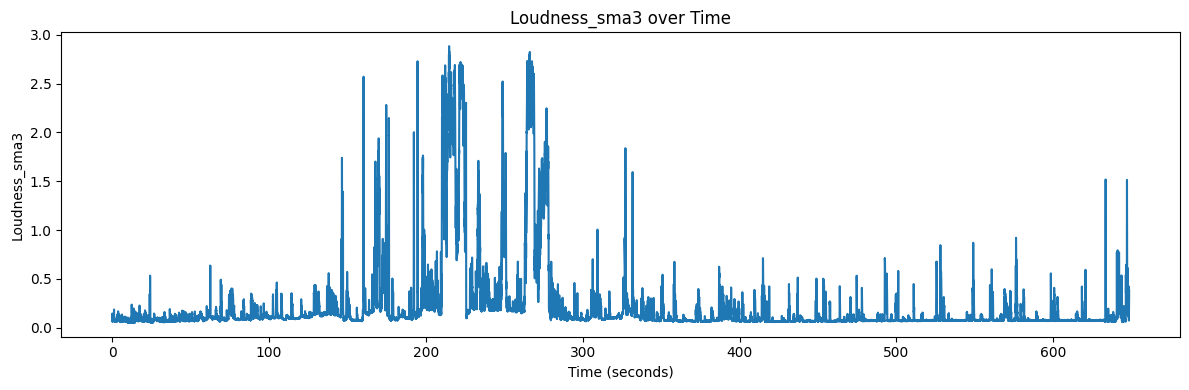

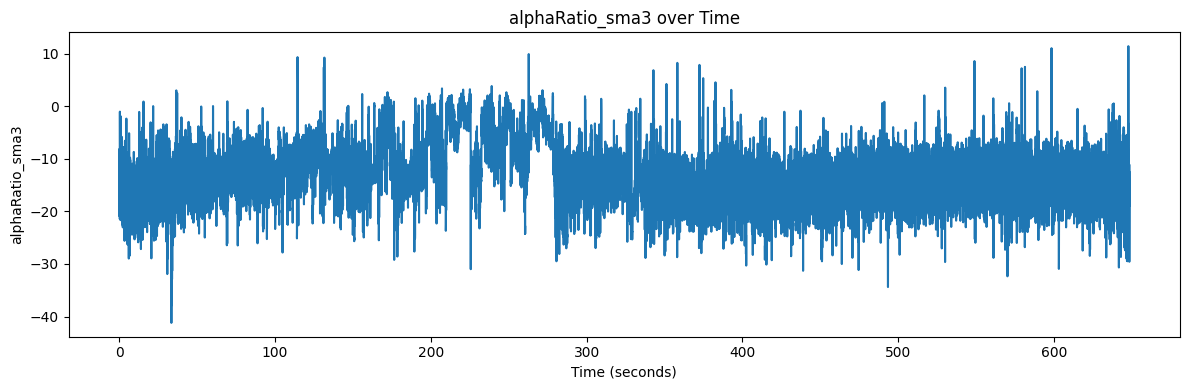

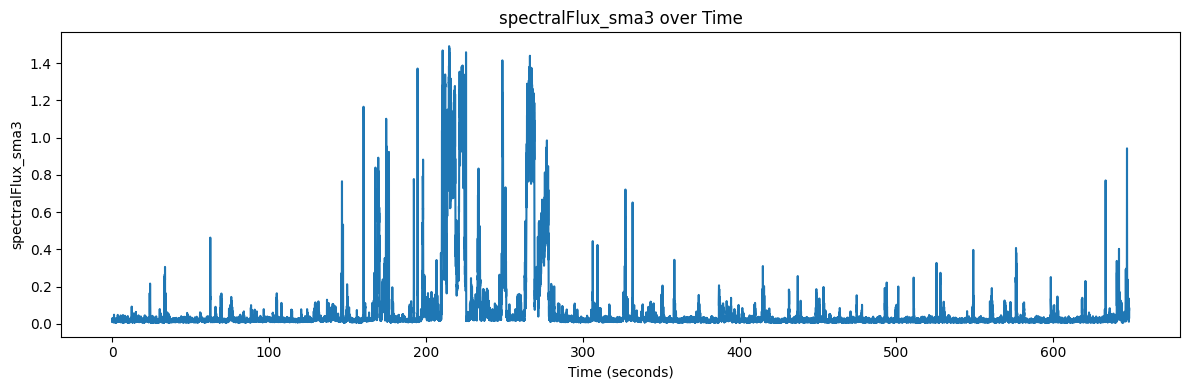

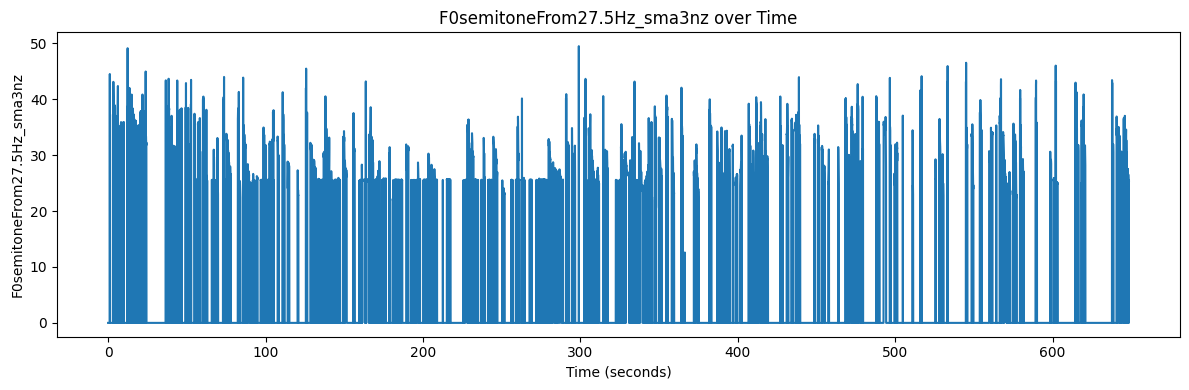

In [ ]:
features_to_plot = [
    "Loudness_sma3",
    "alphaRatio_sma3",
    "spectralFlux_sma3",
    "F0semitoneFrom27.5Hz_sma3nz"
]

for feature in features_to_plot:
    if feature in eg.columns:
        plt.figure(figsize=(12, 4))
        plt.plot(eg["frameTime"], eg[feature])
        plt.xlabel("Time (seconds)")
        plt.ylabel(feature)
        plt.title(f"{feature} over Time")
        plt.tight_layout()
        plt.show()

['pcm_fftMag_mfcc[0]', 'pcm_fftMag_mfcc[1]', 'pcm_fftMag_mfcc[2]', 'pcm_fftMag_mfcc[3]', 'pcm_fftMag_mfcc[4]', 'pcm_fftMag_mfcc[5]', 'pcm_fftMag_mfcc[6]', 'pcm_fftMag_mfcc[7]', 'pcm_fftMag_mfcc[8]', 'pcm_fftMag_mfcc[9]', 'pcm_fftMag_mfcc[10]', 'pcm_fftMag_mfcc[11]', 'pcm_fftMag_mfcc[12]']
Number of MFCC coefficients: 13


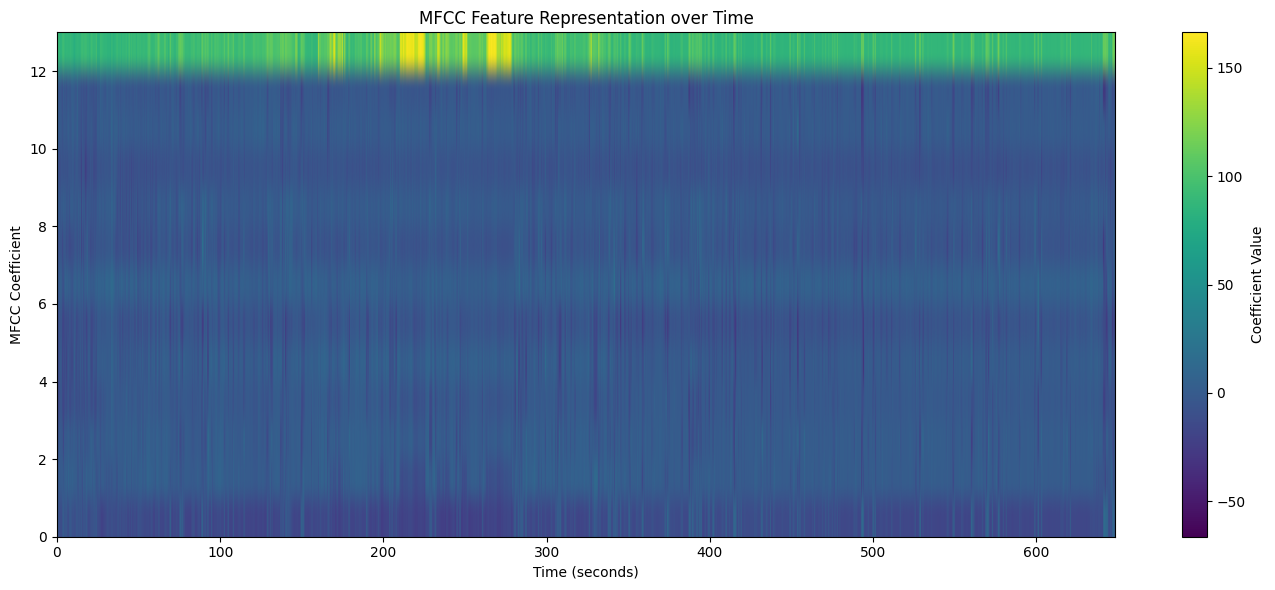

In [ ]:
mfcc_cols = [
    c for c in mfcc.columns
    if "mfcc[" in c
]

print(mfcc_cols)
print("Number of MFCC coefficients:", len(mfcc_cols))

plt.figure(figsize=(14, 6))

plt.imshow(
    mfcc[mfcc_cols].T,
    aspect="auto",
    origin="lower",
    extent=[
        mfcc["frameTime"].min(),
        mfcc["frameTime"].max(),
        0,
        len(mfcc_cols)
    ]
)

plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficient")
plt.title("MFCC Feature Representation over Time")
plt.colorbar(label="Coefficient Value")

plt.tight_layout()
plt.show()

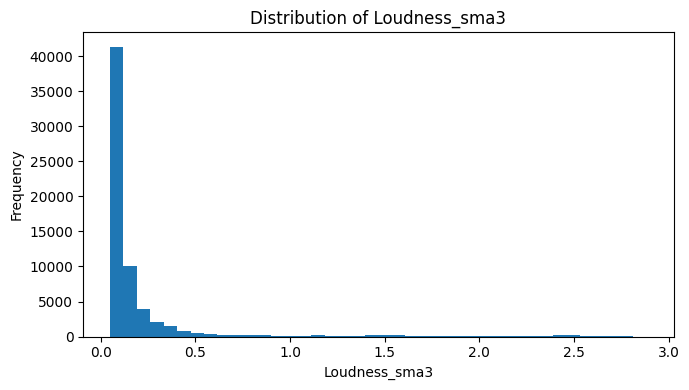

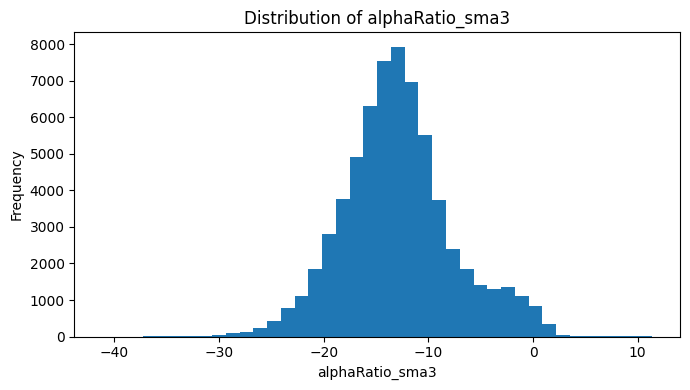

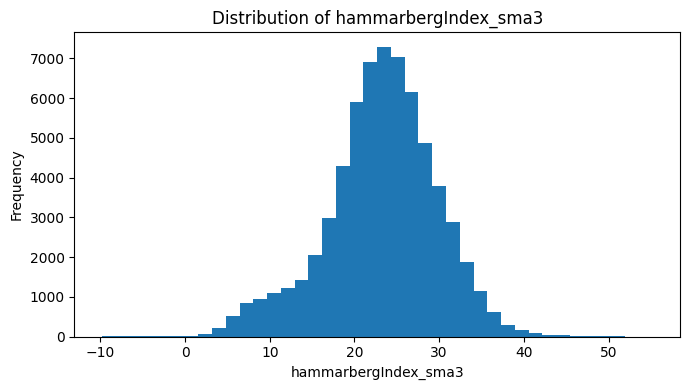

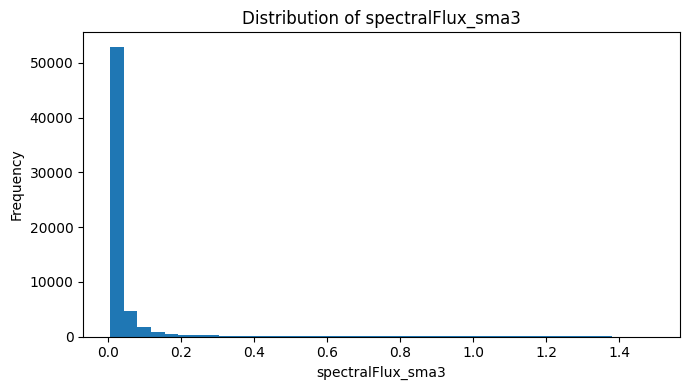

In [ ]:
features_to_plot = [
    "Loudness_sma3",
    "alphaRatio_sma3",
    "hammarbergIndex_sma3",
    "spectralFlux_sma3"
]

for feature in features_to_plot:
    if feature in eg.columns:
        plt.figure(figsize=(7, 4))
        plt.hist(eg[feature].dropna(), bins=40)
        plt.xlabel(feature)
        plt.ylabel("Frequency")
        plt.title(f"Distribution of {feature}")
        plt.tight_layout()
        plt.show()

In [ ]:
print("Unique values in name:")
print(eg["name"].value_counts().head(20))

print("\nNumber of unique names:", eg["name"].nunique())

print("MFCC name values:")
print(mfcc["name"].value_counts().head(20))

Unique values in name:
name
'unknown'    64846
Name: count, dtype: int64

Number of unique names: 1
MFCC name values:
name
'unknown'    64848
Name: count, dtype: int64


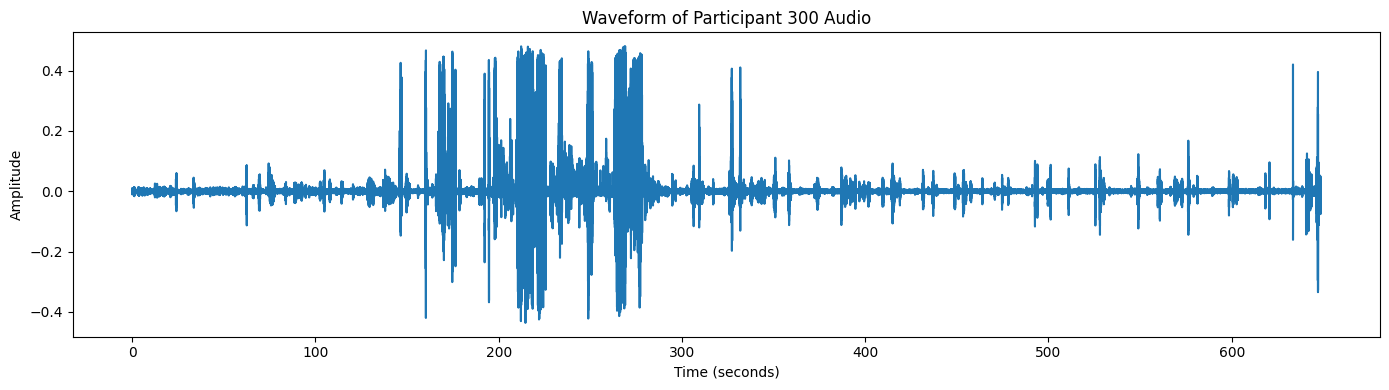

In [ ]:
plt.figure(figsize=(14, 4))

time_axis = np.linspace(0, len(y) / sr, len(y))

plt.plot(time_axis, y)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Waveform of Participant 300 Audio")

plt.tight_layout()
plt.show()